In [2]:
import json, re, sys, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

sys.path.append("../../src")
from validate_adv import invalid_reason, edit_distance, ext
from evaluate import group_evaluation, attack_summary, save_preds
from load_data import load_config

ADV_DIR, RES, MODELS = Path("../../data/adversarial/cnn"), Path("../../results/cnn"), Path("../../models")
for p in (ADV_DIR, RES, MODELS):
    p.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- config ----------------
SEED = 42                          
BUDGET_TRAIN = load_config()[0]["budget"]   
RUN_CONTROL = True                 # also train the duplicated-phishing control model
FORCE_RETRAIN = False              # reuse saved checkpoints if present
THRESHOLD, TOP_POSITIONS = 0.5, 3
NUM_EPOCHS, BATCH_SIZE, LR = 5, 256, 1e-3

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Device:", device, "| train budget k =", BUDGET_TRAIN)

/home/ubuntu/miniconda/envs/dsa4266/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | train budget k = 3


In [3]:
with open("../../data/vocab.json") as f:
    vocab = json.load(f)
with open("../../data/config.json") as f:
    config = json.load(f)
index_to_string = vocab["index_to_string"]
char_to_idx = {c: i for i, c in enumerate(index_to_string)}
PAD_IDX, UNK_IDX, MAX_LEN = vocab["pad_idx"], vocab["unk_idx"], config["max_len"]
VOCAB_SIZE = len(index_to_string)

def canonicalize_model_url(url):
    url = str(url).strip()
    url = re.sub(r"^[A-Za-z][A-Za-z0-9+.\-]*://", "", url)
    url = re.sub(r"^www\d*\.", "", url, flags=re.IGNORECASE)
    return re.sub(r"/+$", "", url)

def encode_batch(urls):
    arr = np.full((len(urls), MAX_LEN), PAD_IDX, dtype=np.int64)
    for r, u in enumerate(urls):
        row = [char_to_idx.get(c, UNK_IDX) for c in u[:MAX_LEN]]
        arr[r, :len(row)] = row
    return torch.from_numpy(arr)

class URLDataset(Dataset):
    def __init__(self, df):
        self.urls, self.labels = df["URL"].tolist(), df["label"].tolist()
    def __len__(self): return len(self.urls)
    def __getitem__(self, i):
        y = 1.0 if self.labels[i] == 0 else 0.0          # phishing = 1
        return encode_batch([self.urls[i]])[0], torch.tensor(y, dtype=torch.float32)

class CharacterCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.conv1 = nn.Conv1d(embedding_dim, 128, kernel_size=5)
        self.conv2 = nn.Conv1d(128, 128, kernel_size=5)
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Linear(128, 1)
    def forward(self, x):
        x = self.embedding(x).transpose(1, 2)
        x = self.relu(self.conv1(x)); x = self.relu(self.conv2(x))
        return self.fc(self.pool(x).squeeze(2))

@torch.no_grad()
def p_phish_with(m, urls, batch_size=1024):
    m.eval(); out = []
    for i in range(0, len(urls), batch_size):
        out.append(torch.sigmoid(m(encode_batch(urls[i:i + batch_size]).to(device)).squeeze(1)).cpu())
    return torch.cat(out).numpy()

# Read data

In [4]:
# original
train_df = pd.read_csv("../../data/train.csv")
val_df = pd.read_csv("../../data/val.csv")
test_df = pd.read_csv("../../data/test.csv")
for d in (train_df, val_df, test_df):
    d["URL"] = d["URL"].apply(canonicalize_model_url)

# original + adversarial (generated from model 1)
train_aug = pd.read_csv(ADV_DIR / "cnn_train_original_and_adversarial.csv", keep_default_na=False)[["URL", "label"]]
n_adv_train = len(train_aug) - len(train_df)
print(f"train_original {len(train_df)} -> augmented {len(train_aug)} (+{n_adv_train} adversarial)")
print("phishing(%) in train:", round((train_df.label == 0).mean(), 4), "->", round((train_aug.label == 0).mean(), 4))
print("train_aug URLs also in test_original (check):", len(set(train_aug.URL) & set(test_df.URL)))

train_original 185397 -> augmented 198032 (+12635 adversarial)
phishing(%) in train: 0.4183 -> 0.4554
train_aug URLs also in test_original (check): 0


# Train Model 2
- validation set is same as original `val.csv`
-  training dataset flips labels to (phishing = 1) --> model outputs P(phishing). 

In [5]:
def train_model(df_train, name, seed=SEED):
    path = MODELS / f"{name}_s{seed}.pt"
    m = CharacterCNN(VOCAB_SIZE, 32).to(device)
    if path.exists() and not FORCE_RETRAIN:
        m.load_state_dict(torch.load(path, map_location=device, weights_only=True)); print("loaded", path.name)
        return m.eval()
    set_seed(seed)
    m = CharacterCNN(VOCAB_SIZE, 32).to(device)
    crit, opt = nn.BCEWithLogitsLoss(), torch.optim.Adam(m.parameters(), lr=LR)
    tl = DataLoader(URLDataset(df_train), batch_size=BATCH_SIZE, shuffle=True)
    vl = DataLoader(URLDataset(val_df), batch_size=BATCH_SIZE, shuffle=False)
    log = []
    for ep in range(NUM_EPOCHS):
        m.train(); tr = 0
        for X, y in tl:
            X, y = X.to(device), y.to(device)
            opt.zero_grad(); loss = crit(m(X).squeeze(1), y); loss.backward(); opt.step(); tr += loss.item()
        m.eval(); va = 0
        with torch.no_grad():
            for X, y in vl:
                X, y = X.to(device), y.to(device); va += crit(m(X).squeeze(1), y).item()
        log.append({"epoch": ep + 1, "train_loss": tr / len(tl), "val_loss": va / len(vl)})
        print(f"[{name}] epoch {ep+1}/{NUM_EPOCHS} train {log[-1]['train_loss']:.4f} val {log[-1]['val_loss']:.4f}")
    torch.save(m.state_dict(), path)
    pd.DataFrame(log).to_csv(RES / f"{name}_s{seed}_train_log.csv", index=False)
    return m.eval()

model1 = CharacterCNN(VOCAB_SIZE, 32).to(device)
model1.load_state_dict(torch.load(MODELS / "cnn_baseline.pt", map_location=device, weights_only=True)); model1.eval()

model2 = train_model(train_aug, "cnn_adv_trained")

models = {"MODEL 1": model1, "MODEL 2": model2}

# train extra control model on original data + sample duplicates of phishing rows 
# so that total dataset size = size of original + adv dataset --> find out whether any gain for MODEL 2 comes from adversarial examples or just from having more phishing rows in training
if RUN_CONTROL:
    extra = train_df[train_df.label == 0].sample(n=n_adv_train, random_state=SEED)   # same count of extra phishing rows
    control_df = pd.concat([train_df, extra], ignore_index=True)
    models["CONTROL (duplicate phishing)"] = train_model(control_df, "cnn_control_dup")

loaded cnn_adv_trained_s42.pt
loaded cnn_control_dup_s42.pt


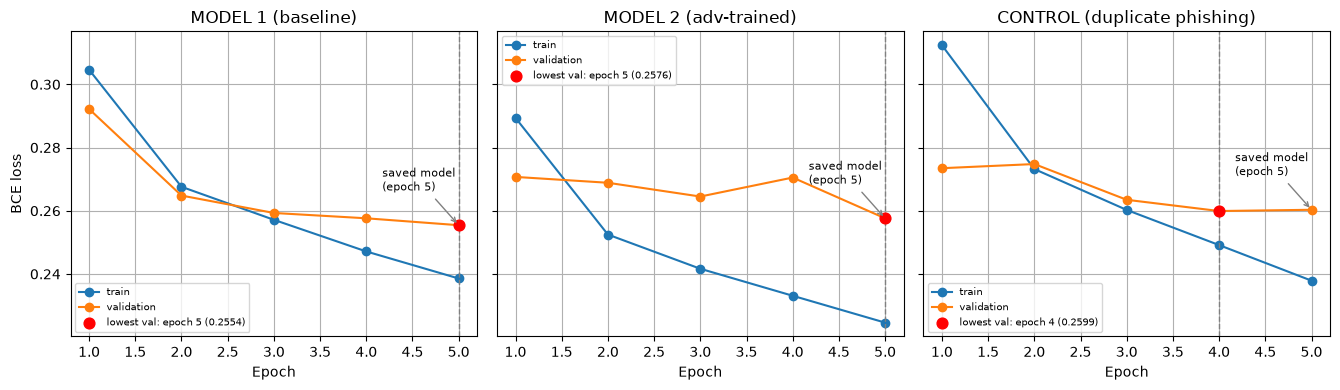

In [13]:

logs = {
    "MODEL 1 (baseline)": RES / "cnn_train_log.csv",
    "MODEL 2 (adv-trained)": RES / f"cnn_adv_trained_s{SEED}_train_log.csv",
    "CONTROL (duplicate phishing)": RES / f"cnn_control_dup_s{SEED}_train_log.csv",
}
logs = {k: v for k, v in logs.items() if v.exists()}          # skips the control if it wasn't run

fig, axes = plt.subplots(1, len(logs), figsize=(4.5 * len(logs), 4), sharey=True, squeeze=False)
for ax, (name, path) in zip(axes[0], logs.items()):
    log = pd.read_csv(path)
    ax.plot(log["epoch"], log["train_loss"], marker="o", label="train")
    ax.plot(log["epoch"], log["val_loss"], marker="o", label="validation")

    best = log.loc[log["val_loss"].idxmin()]                  # lowest val loss, read from the log
    ax.axvline(best["epoch"], color="gray", linestyle="--", linewidth=1)
    ax.scatter([best["epoch"]], [best["val_loss"]], color="red", zorder=3, s=60,
               label=f"lowest val: epoch {int(best['epoch'])} ({best['val_loss']:.4f})")

    final = log.iloc[-1]                                      # the model that was actually saved and evaluated
    ax.annotate(f"saved model\n(epoch {int(final['epoch'])})", (final["epoch"], final["val_loss"]),
                textcoords="offset points", xytext=(-55, 25), fontsize=8,
                arrowprops=dict(arrowstyle="->", color="gray"))

    ax.set_title(name); ax.set_xlabel("Epoch"); ax.grid(True); ax.legend(fontsize=7)
axes[0][0].set_ylabel("BCE loss")
plt.tight_layout()
fig.savefig(RES / f"cnn_m1_m2_loss_curve.png", dpi=300, bbox_inches="tight")   # delete to only view
plt.show()

# Adversarial Attack

In [6]:
HOST_CHARS = "abcdefghijklmnopqrstuvwxyz0123456789-."
PATH_CHARS = "abcdefghijklmnopqrstuvwxyz0123456789-._~/=&?#"
START_CHARS = "/?#"

def char_mask(chars):
    mk = torch.zeros(VOCAB_SIZE, dtype=torch.bool, device=device)
    mk[[char_to_idx[c] for c in chars]] = True
    return mk
REGION_MASKS = torch.stack([char_mask(HOST_CHARS), char_mask(PATH_CHARS), char_mask(START_CHARS)])

model, E, K = model1, None, BUDGET_TRAIN

def set_attack_model(m):
    global model, E
    model = m.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    E = model.embedding.weight.detach()

def p_phish_batch(urls, batch_size=1024):
    return p_phish_with(model, urls, batch_size)

def forward_from_embeddings(emb):
    x = emb.transpose(1, 2)
    x = model.relu(model.conv1(x)); x = model.relu(model.conv2(x))
    return model.fc(model.pool(x).squeeze(2))

def logit_and_embedding_grad(url):
    ids = encode_batch([url]).to(device)
    with torch.inference_mode(False), torch.enable_grad():
        emb = model.embedding(ids).detach().clone().requires_grad_(True)
        logit = forward_from_embeddings(emb).squeeze()
        (grad,) = torch.autograd.grad(logit, emb)
    return ids[0], grad[0]

def url_layout(url):
    n = len(url)
    path_start = next((i for i, c in enumerate(url) if c in "/?#"), n)
    userinfo, at, hostport = url[:path_start].rpartition("@")
    host_start = len(userinfo) + len(at)
    host = hostport.split(":")[0]
    sub = ext(host).subdomain if host else ""
    if not sub or not host.startswith(sub):
        return n, path_start, None
    return n, path_start, (host_start, host_start + len(sub))

def ins_chars(j, layout):
    n, ps, hr = layout
    if hr and hr[0] <= j <= hr[1]: return HOST_CHARS
    if n > ps and ps + 1 <= j <= n: return PATH_CHARS
    if n == ps and j == n: return START_CHARS
    return None

def top_positions(url, layout, m=TOP_POSITIONS):
    n, ps, hr = layout
    ids, grad = logit_and_embedding_grad(url)
    pos, region = [], []
    if hr:
        for i in range(hr[0], min(hr[1], MAX_LEN)):
            pos.append(i); region.append(0)
    for i in range(ps + 1, min(n, MAX_LEN)):
        pos.append(i); region.append(1)
    if n < MAX_LEN:
        pos.append(n); region.append(2 if n == ps else 1)
    if not pos:
        return []
    pos_t = torch.tensor(pos, device=device)
    allowed = REGION_MASKS[torch.tensor(region, device=device)].clone()
    allowed[torch.arange(len(pos), device=device), ids[pos_t]] = False
    gain = -(grad @ E.T) + (grad * E[ids]).sum(1, keepdim=True)
    score = gain[pos_t].masked_fill(~allowed, float("-inf")).max(1).values
    return [pos[t] for t in score.topk(min(m, len(pos))).indices.tolist()]

def gen_candidates(url, positions, layout):
    n, ps, hr = layout
    cands = set()
    for c in PATH_CHARS:
        cands.add(url + c); cands.add(url + "/" + c)
    for i in positions:
        if i >= n:
            for c in ins_chars(n, layout): cands.add(url + c)
            continue
        chars = HOST_CHARS if (hr and hr[0] <= i < hr[1]) else PATH_CHARS
        for c in chars:
            if c != url[i]: cands.add(url[:i] + c + url[i + 1:])
        cands.add(url[:i] + url[i + 1:])
        for j in (i, i + 1):
            ic = ins_chars(j, layout)
            if ic:
                for c in ic: cands.add(url[:j] + c + url[j:])
    cands.discard(url)
    return list(cands)

def attack_url(orig, p_clean):
    url, p_cur = orig, float(p_clean)
    for _ in range(K):
        if p_cur < THRESHOLD: break
        layout = url_layout(url)
        positions = top_positions(url, layout)
        if not positions: break
        cands = gen_candidates(url, positions, layout)
        if not cands: break
        probs = p_phish_batch(cands)
        best = None
        for j in np.argsort(probs):
            if probs[j] >= p_cur: break
            if invalid_reason(orig, cands[j], K) == "":
                best = j; break
        if best is None: break
        url, p_cur = cands[best], float(probs[best])
    return {"orig_URL": orig, "URL": url, "label": 0, "p_clean": float(p_clean), "p_adv": p_cur,
            "n_edits": edit_distance(orig, url), "flipped": p_cur < THRESHOLD}

def select_targets(df):
    # all true-phishing URLs the attacked model currently detects (100%, as in the MODEL 1 test attack)
    phish = df[df["label"] == 0].copy()
    phish["p_clean"] = p_phish_batch(phish["URL"].tolist())
    det = phish[phish["p_clean"] >= THRESHOLD].reset_index(drop=True)
    print(f"phishing {len(phish)} | missed by attacked model {len(phish) - len(det)} | to attack {len(det)}")
    return det

def run_attack(targets, out_csv, chunk=2000):
    out_csv = Path(out_csv)
    done = len(pd.read_csv(out_csv, keep_default_na=False)) if out_csv.exists() else 0
    if done: print(f"{out_csv.name}: resuming {done}/{len(targets)}")
    for start in range(done, len(targets), chunk):
        part = targets.iloc[start:start + chunk]
        rows = [attack_url(u, p) for u, p in tqdm(zip(part["URL"], part["p_clean"]), total=len(part), desc=f"{out_csv.stem} {start}")]
        pd.DataFrame(rows).to_csv(out_csv, mode="a", header=not out_csv.exists(), index=False)
    return pd.read_csv(out_csv, keep_default_na=False)

In [7]:
# load m1 adversarial examples 
adv_m1 = pd.read_csv(ADV_DIR / "cnn_test_adversarial.csv", keep_default_na=False)
adv_m1["duplicate"] = adv_m1["duplicate"].astype(str).eq("True")

def mark_duplicates(adv, split_df): 
    adv = adv.copy()
    adv["duplicate"] = (adv["n_edits"] > 0) & (adv["URL"].isin(split_df["URL"]) | adv["URL"].duplicated())
    return adv

# generate m2 adversarial examples
set_attack_model(model2)
targets_m2 = select_targets(test_df)               
adv_m2 = run_attack(targets_m2, ADV_DIR / "cnn_m2_test_adversarial.csv")

assert all(invalid_reason(o, a, K) == "" for o, a in zip(adv_m2["orig_URL"], adv_m2["URL"])), "invalid adversarial URLs"
assert (adv_m2["n_edits"] <= K).all()
adv_m2 = mark_duplicates(adv_m2, test_df)

for name, a in (("adv(M1)", adv_m1), ("adv(M2)", adv_m2)):
    s_ = attack_summary(a, K)
    print(name, {k: s_[k] for k in ("attacked", "flipped", "edited_not_flipped", "not_edited", "duplicates_dropped")},
          "| success within k:", round(s_["success_within_edits"][K], 4))
import json as _json
(RES / "cnn_m2_adv_test_summary.json").write_text(_json.dumps(attack_summary(adv_m2, K), indent=1))

phishing 9694 | missed by attacked model 1847 | to attack 7847


cnn_m2_test_adversarial 0:   0%|          | 0/2000 [00:00<?, ?it/s]/home/ubuntu/miniconda/envs/dsa4266/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
cnn_m2_test_adversarial 6000: 100%|██████████| 1847/1847 [01:14<00:00, 24.90it/s]


adv(M1) {'attacked': 7939, 'flipped': 333, 'edited_not_flipped': 6747, 'not_edited': 859, 'duplicates_dropped': 613} | success within k: 0.0419
adv(M2) {'attacked': 7847, 'flipped': 55, 'edited_not_flipped': 6323, 'not_edited': 1469, 'duplicates_dropped': 497} | success within k: 0.007


489

# Evaluation on test set
- Sets 2 and 3 are phishing-heavier than set 1, so recall rises for *every* model on them. Don't read that increase as robustness; compare models *within* a set.
- `fpr` on set 1 is the cost of adversarial training.
- web.app is all phishing, only look at recall-type metrics (`recall`, `adversarial_recall`, `robust_recall`, `attack_success_rate`); `fpr`, precision, F1 and the AUCs are `nan`.
- `adversarial_recall`: share of the edited, non-duplicate adversarial URLs the model still detects.
- `attack_success_rate`: has a different denominator for each model (the phishing URLs that model detected clean), cannot be compared across models.
- `robust_recall`: share of all true-phishing test URLs the model detects both before and after the attack (an unattacked URL counts if it is detected clean). The denominator is fixed --> MODEL 1 and MODEL 2 are directly comparable

In [9]:
def eval_groups(m, adv):
    p_test = p_phish_with(m, test_df["URL"].tolist())
    return group_evaluation(test_df, p_test, adv,
                            p_phish_with(m, adv["orig_URL"].tolist()),   #score on the original
                            p_phish_with(m, adv["URL"].tolist()))        # score on the adv

mkey = {"MODEL 1": "m1", "MODEL 2": "m2", "CONTROL (duplicate phishing)": "control"}

parts_ = []
for mn, m in models.items():
    save_preds(RES / f"cnn_{mkey[mn]}_test_preds_s{SEED}.csv", test_df["URL"], test_df["label"],
               p_phish_with(m, test_df["URL"].tolist()))
    for src_, adv in (("MODEL 1", adv_m1), ("MODEL 2", adv_m2)):
        r = eval_groups(m, adv)
        r["fpr"] = r["confusion_matrix"].map(
            lambda c: c[1][0] / sum(c[1]) if isinstance(c, list) and sum(c[1]) else float("nan"))
        r.insert(0, "attacks from", src_); r.insert(0, "model", mn)
        parts_.append(r)
res = pd.concat(parts_, ignore_index=True)

cols = ["accuracy", "precision", "recall", "f1", "fpr", "roc_auc", "attack_success_rate", "n_attempts",
        "adversarial_recall", "robust_recall", "delta_recall"]

# set 1 (test_original): identical for both attack sources, so show it once
set1 = res[(res["test_set"] == "test_original") & (res["attacks from"] == "MODEL 1")]
display(set1.set_index(["model", "group"])[cols[:6]].round(4))

# sets 2 and 3: test_original + adversarial rows from MODEL 1 / MODEL 2
mixed = res[res["test_set"] != "test_original"]
display(mixed.set_index(["model", "attacks from", "group"])[cols].round(4))

res.drop(columns="confusion_matrix").to_csv(RES / f"cnn_group_eval_s{SEED}.csv", index=False)

accuracy  precision  recall      f1  \
model                        group                                          
MODEL 1                      all        0.9043     0.9448  0.8190  0.8774   
                             web.app       NaN        NaN  1.0000     NaN   
                             other      0.8737     0.8342  0.5708  0.6778   
MODEL 2                      all        0.9064     0.9605  0.8095  0.8785   
                             web.app       NaN        NaN  1.0000     NaN   
                             other      0.8765     0.8741  0.5483  0.6739   
CONTROL (duplicate phishing) all        0.9056     0.9636  0.8047  0.8770   
                             web.app       NaN        NaN  1.0000     NaN   
                             other      0.8755     0.8816  0.5371  0.6675   

                                         fpr  roc_auc  
model                        group                     
MODEL 1                      all      0.0344   0.9413  
                             web.app     NaN      NaN  
                             other    0.0344   0.8613  
MODEL 2                      all      0.0240   0.9414  
                             web.app     NaN      NaN  
                             other    0.0240   0.8613  
CONTROL (duplicate phishing) all      0.0219   0.9414  
                             web.app     NaN      NaN  
                             other    0.0219   0.8614

accuracy  precision  \
model                        attacks from group                          
MODEL 1                      MODEL 1      all        0.9139     0.9681   
                                          web.app       NaN        NaN   
                                          other      0.8673     0.8836   
                             MODEL 2      all        0.9228     0.9675   
                                          web.app       NaN        NaN   
                                          other      0.8786     0.8713   
MODEL 2                      MODEL 1      all        0.9264     0.9779   
                                          web.app       NaN        NaN   
                                          other      0.8856     0.9203   
                             MODEL 2      all        0.9235     0.9769   
                                          web.app       NaN        NaN   
                                          other      0.8791     0.9031   
CONTROL (duplicate phishing) MODEL 1      all        0.9227     0.9796   
                                          web.app       NaN        NaN   
                                          other      0.8805     0.9244   
                             MODEL 2      all        0.9231     0.9788   
                                          web.app       NaN        NaN   
                                          other      0.8791     0.9100   

                                                   recall      f1     fpr  \
model                        attacks from group                             
MODEL 1                      MODEL 1      all      0.8708  0.9169  0.0344   
                                          web.app  0.9980     NaN     NaN   
                                          other    0.6302  0.7357  0.0344   
                             MODEL 2      all      0.8857  0.9248  0.0344   
                                          web.app  0.9990     NaN     NaN   
                                          other    0.6396  0.7377  0.0344   
MODEL 2                      MODEL 1      all      0.8850  0.9292  0.0240   
                                          web.app  1.0000     NaN     NaN   
                                          other    0.6676  0.7739  0.0240   
                             MODEL 2      all      0.8779  0.9248  0.0240   
                                          web.app  0.9999     NaN     NaN   
                                          other    0.6130  0.7303  0.0240   
CONTROL (duplicate phishing) MODEL 1      all      0.8764  0.9251  0.0219   
                                          web.app  0.9988     NaN     NaN   
                                          other    0.6451  0.7599  0.0219   
                             MODEL 2      all      0.8754  0.9243  0.0219   
                                          web.app  0.9989     NaN     NaN   
                                          other    0.6073  0.7284  0.0219   

                                                   roc_auc  \
model                        attacks from group              
MODEL 1                      MODEL 1      all       0.9616   
                                          web.app      NaN   
                                          other     0.8924   
                             MODEL 2      all       0.9631   
                                          web.app      NaN   
                                          other     0.8840   
MODEL 2                      MODEL 1      all       0.9647   
                                          web.app      NaN   
                                          other     0.8982   
                             MODEL 2      all       0.9631   
                                          web.app      NaN   
                                          other     0.8837   
CONTROL (duplicate phishing) MODEL 1      all       0.9630   
                                          web.app      NaN   
                                     